In [265]:
# import everything
import os
from collections import deque
from itertools import islice
import csv

import gcsfs
import imageio
import matplotlib.pyplot as plt
import numpy as np
import tifffile
from scipy.ndimage import binary_closing, binary_fill_holes, median_filter
from skimage.filters import gaussian, threshold_otsu
from skimage.measure import label, regionprops
from skimage.morphology import binary_dilation, disk
from sklearn.mixture import GaussianMixture

In [266]:
'''
Files list:

20250311_Fly1_1_MMStack_Default.ome.tif
20250311_Fly1_2_MMStack_Default.ome.tif
20250311_Fly1_3_MMStack_Default.ome.tif
20250311_Fly1_4_MMStack_Default.ome.tif
20250311_Fly1_5_MMStack_Default.ome.tif
20250311_Fly1_6_MMStack_Default.ome.tif
20250311_Fly2_1_MMStack_Default.ome.tif
20250311_Fly2_2_MMStack_Default.ome.tif
20250311_Fly2_3_MMStack_Default.ome.tif
20250511_1_MMStack_Default_0.ome.tif
20250511_1_MMStack_Default_1.ome.tif
20250511_1_MMStack_Default_2.ome.tif
20250511_2_MMStack_Default_0.ome.tif
20250511_2_MMStack_Default_1.ome.tif
20250511_2_MMStack_Default_2.ome.tif
20250711_Fly1_1_MMStack_Default.ome.tif
20250711_Fly1_2_MMStack_Default.ome.tif
20250711_Fly2_1_MMStack_Default.ome.tif
20250711_Fly2_2_MMStack_Default.ome.tif

'''

'\nFiles list:\n\n20250311_Fly1_1_MMStack_Default.ome.tif\n20250311_Fly1_2_MMStack_Default.ome.tif\n20250311_Fly1_3_MMStack_Default.ome.tif\n20250311_Fly1_4_MMStack_Default.ome.tif\n20250311_Fly1_5_MMStack_Default.ome.tif\n20250311_Fly1_6_MMStack_Default.ome.tif\n20250311_Fly2_1_MMStack_Default.ome.tif\n20250311_Fly2_2_MMStack_Default.ome.tif\n20250311_Fly2_3_MMStack_Default.ome.tif\n20250511_1_MMStack_Default_0.ome.tif\n20250511_1_MMStack_Default_1.ome.tif\n20250511_1_MMStack_Default_2.ome.tif\n20250511_2_MMStack_Default_0.ome.tif\n20250511_2_MMStack_Default_1.ome.tif\n20250511_2_MMStack_Default_2.ome.tif\n20250711_Fly1_1_MMStack_Default.ome.tif\n20250711_Fly1_2_MMStack_Default.ome.tif\n20250711_Fly2_1_MMStack_Default.ome.tif\n20250711_Fly2_2_MMStack_Default.ome.tif\n\n'

In [267]:
filename = "20250511_2_MMStack_Default_2.ome.tif"   # change filename as needed
temp_dir = "temp"                                      # everything made locally goes here; delete this folder when done
bucket_path = f"cv-project-storage/inputs/{filename}"      # no gs:// prefix
local_path = f"{temp_dir}/{filename}"
fs = gcsfs.GCSFileSystem()

# copy the file from the bucket once; skipped if it is already on this machine
if not os.path.exists(local_path):
    os.makedirs(temp_dir, exist_ok=True)
    fs.get(bucket_path, local_path + ".part")
    os.replace(local_path + ".part", local_path)
print(f"{local_path}: {os.path.getsize(local_path) / 1e9:.1f} GB")

temp/20250511_2_MMStack_Default_2.ome.tif: 4.2 GB


In [268]:
path = local_path    # every later cell reads this local copy

with tifffile.TiffFile(path) as tif:
    n_frames = len(tif.pages)
    first = tif.pages[0].asarray()

print("frames:", n_frames)
print("frame shape:", first.shape, first.dtype)

# pixel sizes below were tuned on a 688x512 image; scale them to this file's frame size
scale = np.sqrt(first.shape[0] * first.shape[1] / (688 * 512))   # 1.0 for a 688x512 frame
SIGMA = 2 * scale                              # smoothing width (pixels)
SLOT_GROW = max(1, round(10 * scale))          # how far to grow the slot mask (pixels)
CLOSE_R = max(1, round(3 * scale))             # radius for closing gaps in the fly mask (pixels)
print(f"scale {scale:.2f}: SIGMA={SIGMA:.1f}, SLOT_GROW={SLOT_GROW}, CLOSE_R={CLOSE_R}")

frames: 5908
frame shape: (512, 688) uint16
scale 1.00: SIGMA=2.0, SLOT_GROW=10, CLOSE_R=3


/tmp/ipykernel_13906/1685438710.py:13: FutureWarning: `binary_dilation` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.dilation` instead. Note the lack of mirroring for non-symmetric footprints (see docstring notes).
  slot = binary_dilation(slot, disk(SLOT_GROW))       # grow it so the edges are fully covered


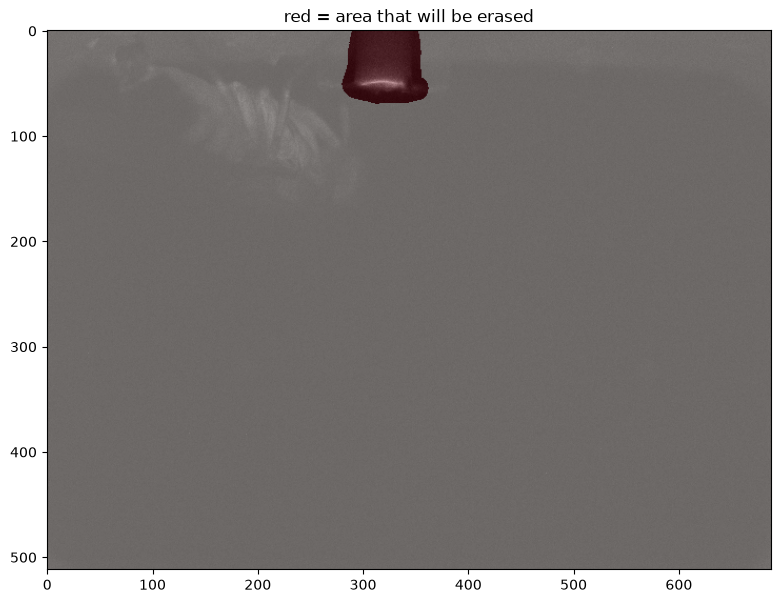

[None]

In [269]:
# getting rid of the slot at the top: find it in 50 frames spread across the video and vote
idx = np.linspace(0, n_frames - 1, 50, dtype=int)
sample_frames = tifffile.imread(path, key=idx.tolist())

votes = np.zeros(sample_frames.shape[1:], np.float32)
for fr in sample_frames:
    ref = gaussian(fr.astype(np.float32), sigma=SIGMA)
    lab = label(ref > threshold_otsu(ref))
    biggest = max(regionprops(lab), key=lambda r: r.area)
    votes += (lab == biggest.label)

slot = votes / len(sample_frames) > 0.5     # part of the slot in most frames
slot = binary_dilation(slot, disk(SLOT_GROW))       # grow it so the edges are fully covered

show = sample_frames[len(sample_frames) // 2]
plt.figure(figsize=(10, 7))
plt.imshow(show, cmap="gray")
plt.imshow(slot, cmap="Reds", alpha=0.4)    # slot mask overlaid in red
plt.title("red = area that will be erased")
plt.show()

np.save(f"{temp_dir}/slot_mask.npy", slot)              # save it so you can reload later
stem = filename.replace(".ome.tif", "")
fs.put(f"{temp_dir}/slot_mask.npy", f"cv-project-storage/outputs/{stem}_slot_mask.npy")

In [270]:
def fly_mask(frame, slot=slot, k=5):
    img = gaussian(frame.astype(np.float32), sigma=SIGMA)
    rest = img[~slot]
    bg = np.median(rest)                                   # typical background brightness
    noise = np.median(np.abs(rest - bg)) * 1.4826          # how much the background varies
    img[slot] = bg
    binary = img > bg + k * noise                          # "clearly brighter than background"
    binary = binary_fill_holes(binary_closing(binary, disk(CLOSE_R)))   # smooth edges, fill gaps
    lab = label(binary)
    fly = max(regionprops(lab), key=lambda r: r.area)
    return lab == fly.label, fly

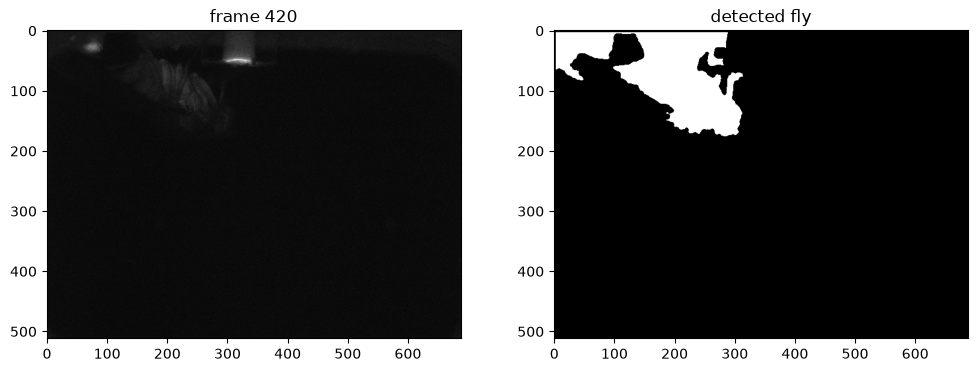

In [271]:
i = np.random.randint(n_frames)                  # random frame from the whole file
frame = tifffile.imread(path, key=i)
mask, fly = fly_mask(frame)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].imshow(frame, cmap="gray"); ax[0].set_title(f"frame {i}")
ax[1].imshow(mask, cmap="gray");  ax[1].set_title("detected fly")
plt.show()

In [272]:
def fly_mask_safe(frame):
    try:
        return fly_mask(frame)
    except ValueError:               # no blob found in this frame
        return np.zeros(frame.shape, bool), None

def iter_frames(path):
    with tifffile.TiffFile(path) as tif:
        for page in tif.pages:
            yield page.asarray()

In [273]:
def side_features(path, k=7):
    feats, iou = [], []
    recent = deque(maxlen=k + 1)
    for i, f in enumerate(iter_frames(path)):
        mask, fly = fly_mask_safe(f)
        recent.append(mask)

        if fly is None:
            feats.append([np.nan] * 5)
        else:
            ys, xs = np.nonzero(mask)
            th = fly.orientation
            dr, dc = np.cos(th), np.sin(th)
            if dc < 0:
                dr, dc = -dr, -dc
            proj = (ys - fly.centroid[0]) * dr + (xs - fly.centroid[1]) * dc
            skew = np.mean(proj**3) / (np.std(proj)**3 + 1e-9)
            feats.append([fly.centroid[1], fly.centroid[0],
              fly.axis_major_length,
              fly.axis_major_length / (fly.axis_minor_length + 1e-9),
              skew])
        if len(recent) == k + 1:
            a, b = recent[-1], recent[0]
            union = (a | b).sum()
            iou.append((a & b).sum() / union if union else np.nan)
        else:
            iou.append(np.nan)

        if i % 500 == 0:
            print(f"frame {i}/{n_frames}")
    return np.array(feats), np.array(iou)

feats, iou = side_features(path)
cx, cy, length, aspect, skew = feats.T
np.savez(f"{temp_dir}/features.npz", feats=feats, iou=iou)   # save so you don't have to recompute
fs.put(f"{temp_dir}/features.npz", f"cv-project-storage/outputs/{stem}_features.npz")
print("done:", feats.shape)

frame 0/5908
frame 500/5908
frame 1000/5908
frame 1500/5908
frame 2000/5908
frame 2500/5908
frame 3000/5908
frame 3500/5908
frame 4000/5908
frame 4500/5908
frame 5000/5908
frame 5500/5908
done: (5908, 5)


quiescent: 50% of frames | 10 bouts
movement bouts: 11


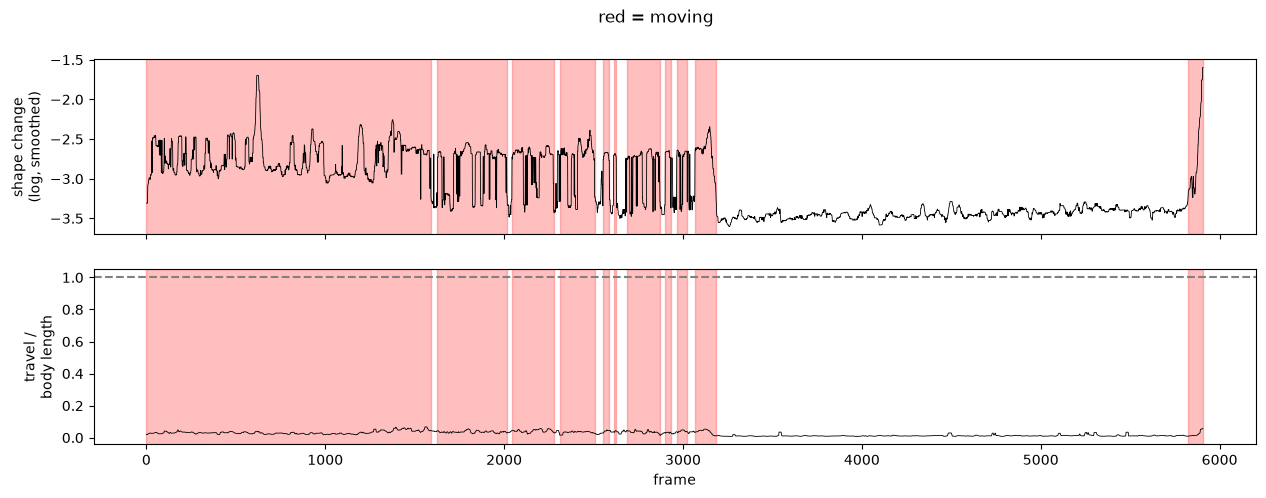

In [274]:
SMOOTH_S    = 3     # smooth features over this many seconds
N_COMP      = 3     # 3 = only the biggest-change group counts as moving; 2 = more sensitive
MIN_MOVE_S  = 2     # movement shorter than this is ignored
MIN_QUIET_S = 3     # quiescence shorter than this is ignored

fps = 7.46
sw = int(SMOOTH_S * fps) | 1                       # odd window length in frames

# Translation: distance traveled in ~1 s, as a fraction of body length
body_len = np.nanpercentile(length, 95)
step = np.concatenate([[0], np.hypot(np.diff(cx), np.diff(cy))])
travel = np.convolve(np.nan_to_num(step), np.ones(7), mode="same") / body_len
travel_s = median_filter(travel, sw)

# Shape change, smoothed
shape = np.log(1 - iou + 1e-4)
shape = np.where(np.isnan(shape), np.nanmedian(shape), shape)
shape_s = median_filter(shape, sw)

gmm = GaussianMixture(N_COMP, random_state=0).fit(shape_s.reshape(-1, 1))
moving_shape = gmm.predict(shape_s.reshape(-1, 1)) == np.argmax(gmm.means_.ravel())

moving = (travel_s >= 1) | moving_shape

def runs(m):
    d = np.diff(np.concatenate([[0], m.astype(int), [0]]))
    return list(zip(np.where(d == 1)[0], np.where(d == -1)[0]))

for s, e in runs(moving):                          # drop short movements
    if e - s < MIN_MOVE_S * fps:
        moving[s:e] = False
for s, e in runs(~moving):                         # drop short quiescence
    if e - s < MIN_QUIET_S * fps:
        moving[s:e] = True

quiet_bouts = runs(~moving)
print(f"quiescent: {(~moving).mean():.0%} of frames | {len(quiet_bouts)} bouts")
print(f"movement bouts: {len(runs(moving))}")

# ---- check plot ----
t = np.arange(len(moving))
fig, ax = plt.subplots(2, 1, figsize=(15, 5), sharex=True)
ax[0].plot(t, shape_s, lw=0.6, color="black"); ax[0].set_ylabel("shape change\n(log, smoothed)")
ax[1].plot(t, travel_s, lw=0.6, color="black"); ax[1].axhline(1, ls="--", color="gray")
ax[1].set_ylabel("travel /\nbody length"); 
ax[1].set_xlabel("frame") 
for a in ax:
    for s, e in runs(moving):
        a.axvspan(s, e, color="red", alpha=0.25)
plt.suptitle("red = moving")
with fs.open(f"cv-project-storage/quiescent_bouts/{filename.replace('.ome.tif', '')}_check_plot.svg", "wb") as out:
    fig.savefig(out, format="svg")  
plt.show()

In [275]:
# temporarily commented out to run all the files
'''START, N = 500, 3000      

sample = tifffile.imread(path, key=range(0, n_frames, 200))
lo, hi = np.percentile(sample, [1, 99.5])
GREEN, RED = np.array([0, 255, 0]), np.array([255, 0, 0])

writer = imageio.get_writer(f"{temp_dir}/clip_{START}.mp4", fps=15, codec="libx264", quality=7)
for i, f in enumerate(islice(iter_frames(path), START, START + N), start=START):
    g = (np.clip((f - lo) / (hi - lo), 0, 1) * 255).astype(np.uint8)
    rgb = np.stack([g, g, g], axis=-1).astype(np.float32)
    mask, _ = fly_mask_safe(f)
    rgb[mask] = 0.6 * rgb[mask] + 0.4 * (RED if moving[i] else GREEN)
    writer.append_data(rgb.astype(np.uint8))
writer.close()
print("saved clip")'''

'START, N = 500, 3000      \n\nsample = tifffile.imread(path, key=range(0, n_frames, 200))\nlo, hi = np.percentile(sample, [1, 99.5])\nGREEN, RED = np.array([0, 255, 0]), np.array([255, 0, 0])\n\nwriter = imageio.get_writer(f"{temp_dir}/clip_{START}.mp4", fps=15, codec="libx264", quality=7)\nfor i, f in enumerate(islice(iter_frames(path), START, START + N), start=START):\n    g = (np.clip((f - lo) / (hi - lo), 0, 1) * 255).astype(np.uint8)\n    rgb = np.stack([g, g, g], axis=-1).astype(np.float32)\n    mask, _ = fly_mask_safe(f)\n    rgb[mask] = 0.6 * rgb[mask] + 0.4 * (RED if moving[i] else GREEN)\n    writer.append_data(rgb.astype(np.uint8))\nwriter.close()\nprint("saved clip")'

In [276]:
# save the quiescent bouts as a CSV (start/end frame of each bout) and upload it
csv_name = f"{stem}_quiescent_bouts.csv"
csv_path = f"{temp_dir}/{csv_name}"

with open(csv_path, "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["file", "bout", "start_frame", "end_frame", "n_frames"])   # end_frame is not included
    for k, (s, e) in enumerate(quiet_bouts):
        w.writerow([filename, k, s, e, e - s])

fs.put(csv_path, f"cv-project-storage/quiescent_bouts/{csv_name}")   # no gs:// prefix
print(f"saved {len(quiet_bouts)} bouts to gs://cv-project-storage/quiescent_bouts/{csv_name}")

saved 10 bouts to gs://cv-project-storage/quiescent_bouts/20250511_2_MMStack_Default_2_quiescent_bouts.csv
